<a href="https://colab.research.google.com/github/OJB-Quantum/Notebooks-for-Ideas/blob/main/GPU_Accelerated_Calculation_for_Reducing_Microplastics_to_Atoms_in_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Authored by Onri Jay Benally (2026)

Open Access (CC-BY-4.0)

In [ ]:
!pip uninstall -y -q cupy cupy-cuda11x cupy-cuda12x cupy-cuda13x
!pip install -q uv
!uv pip install --system --quiet "numpy>=1.26.0" "scipy>=1.11.0" "matplotlib>=3.8.0" "cupy-cuda12x[ctk]"

Backend: gpu | device: {'available': True, 'name': 'Tesla T4', 'free_bytes': 15514533888, 'total_bytes': 15637086208}
Model: 15 gas species, 11 reversible edges; rate coefficients are inputs.
Computing restricted equilibrium map...
Integrating comparison parcels...
Integrating 576 density/expansion parcels...
Integrating 256 rate-sensitivity samples...
Checking conservation, convergence, and independent references...
Timing warmed execution backends...
Rendering plots...


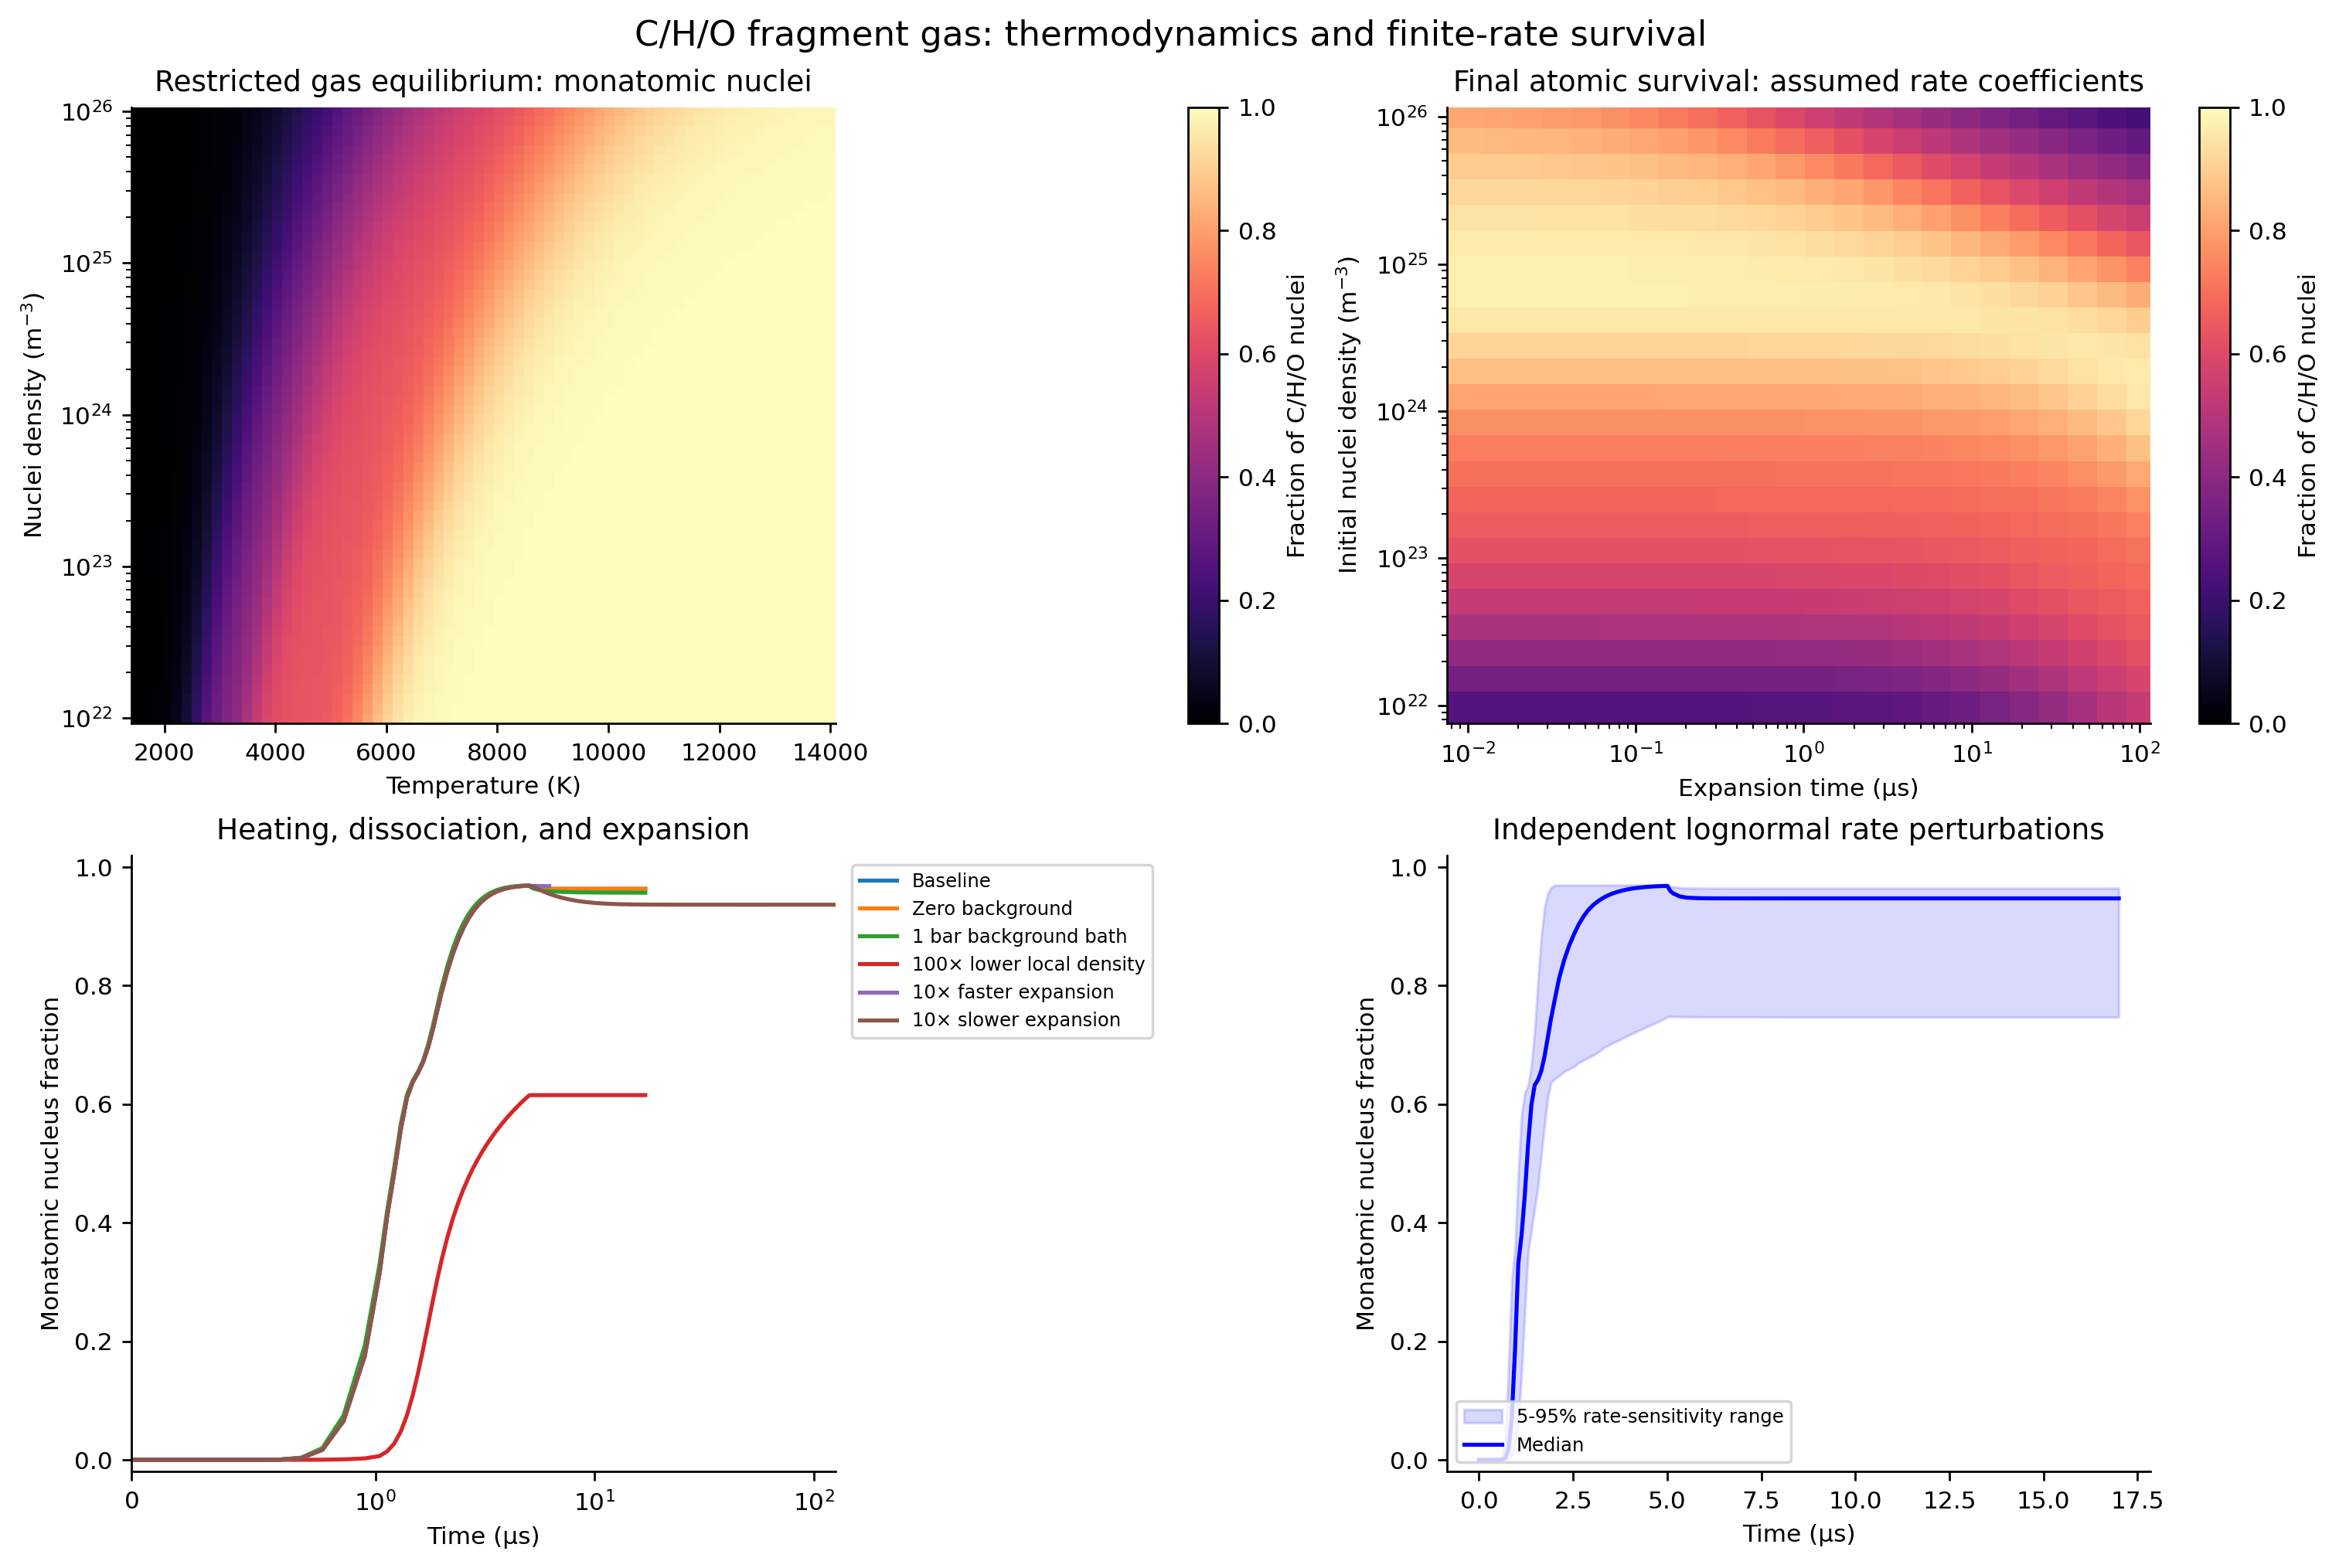

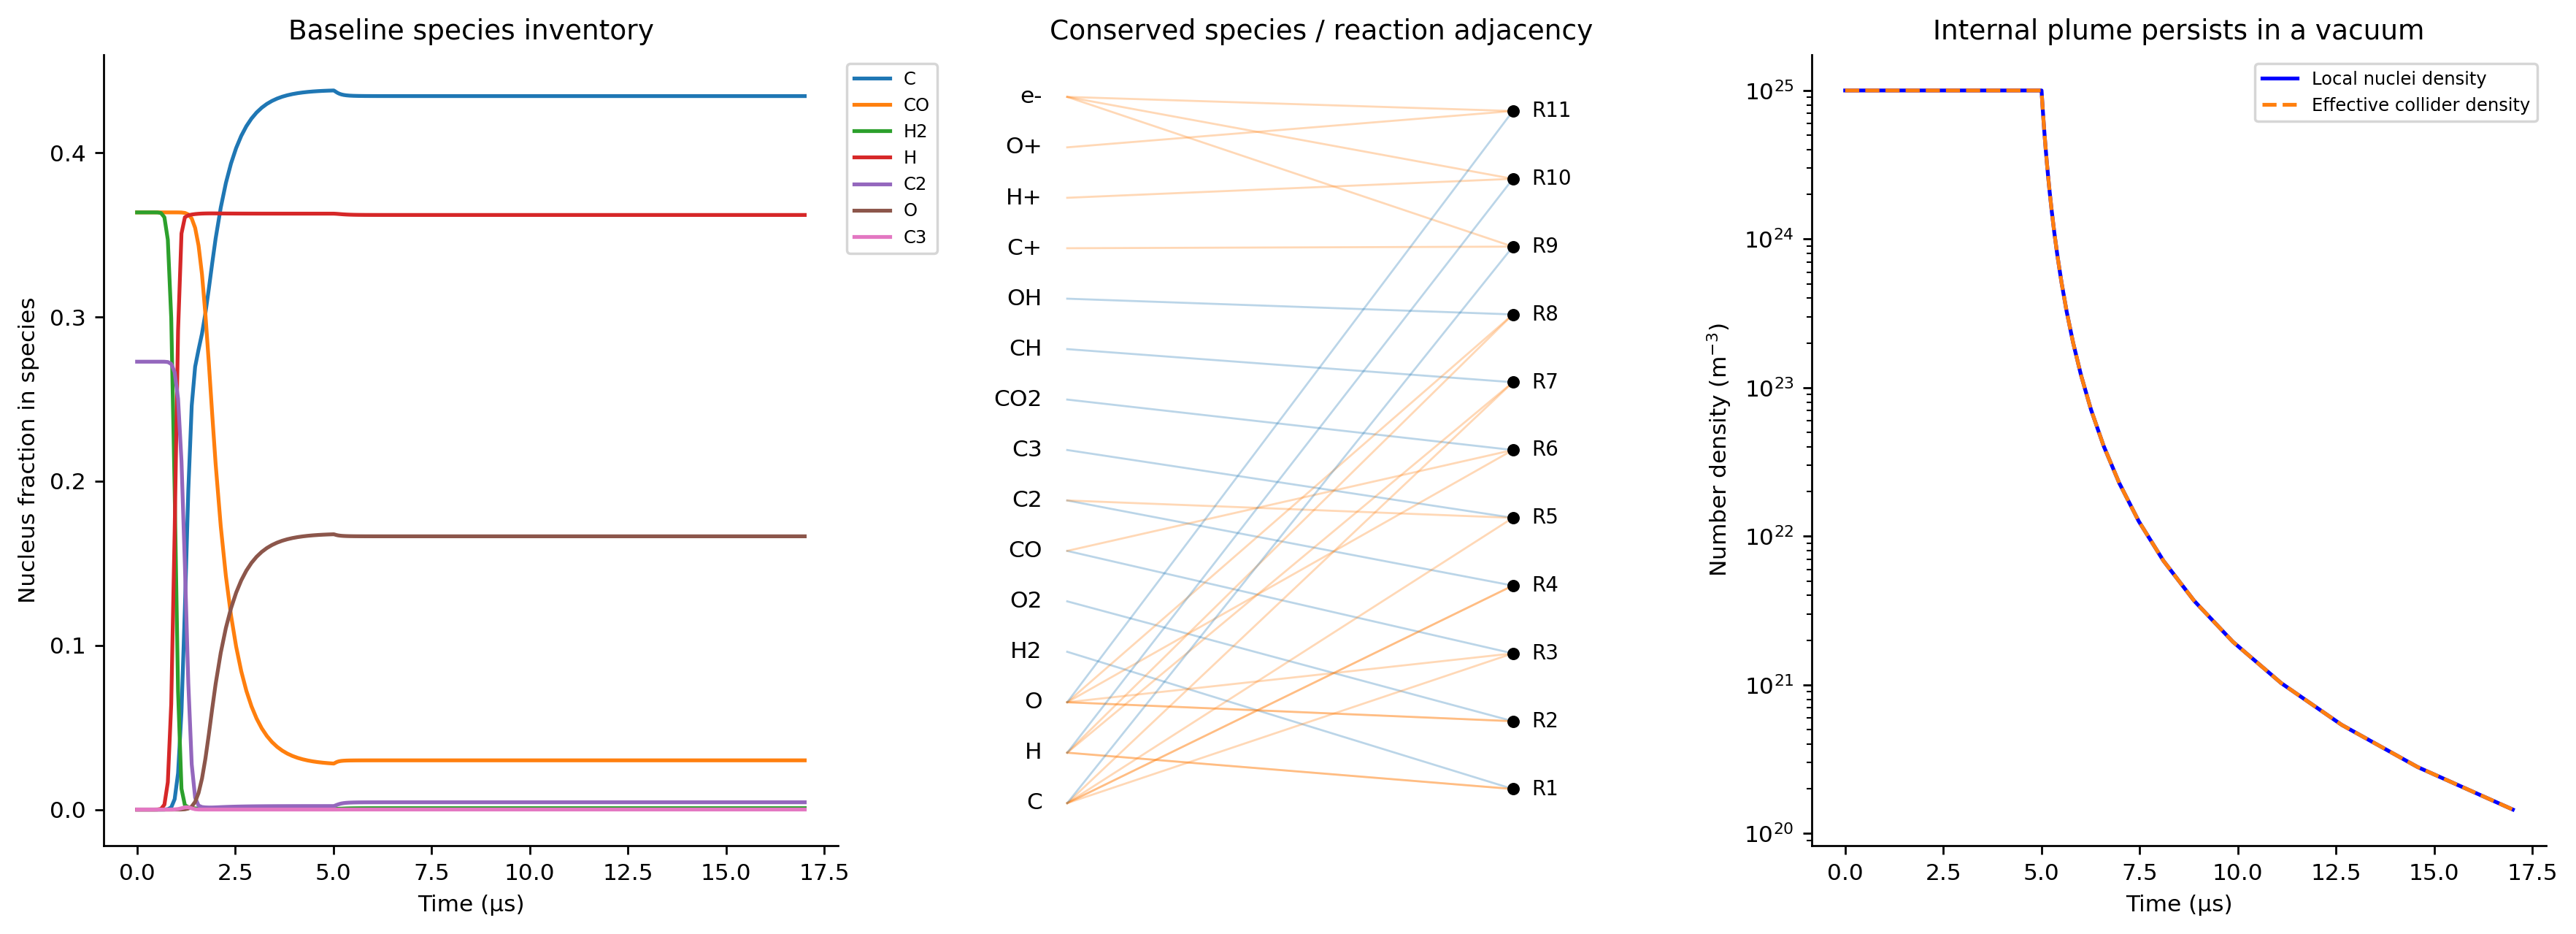

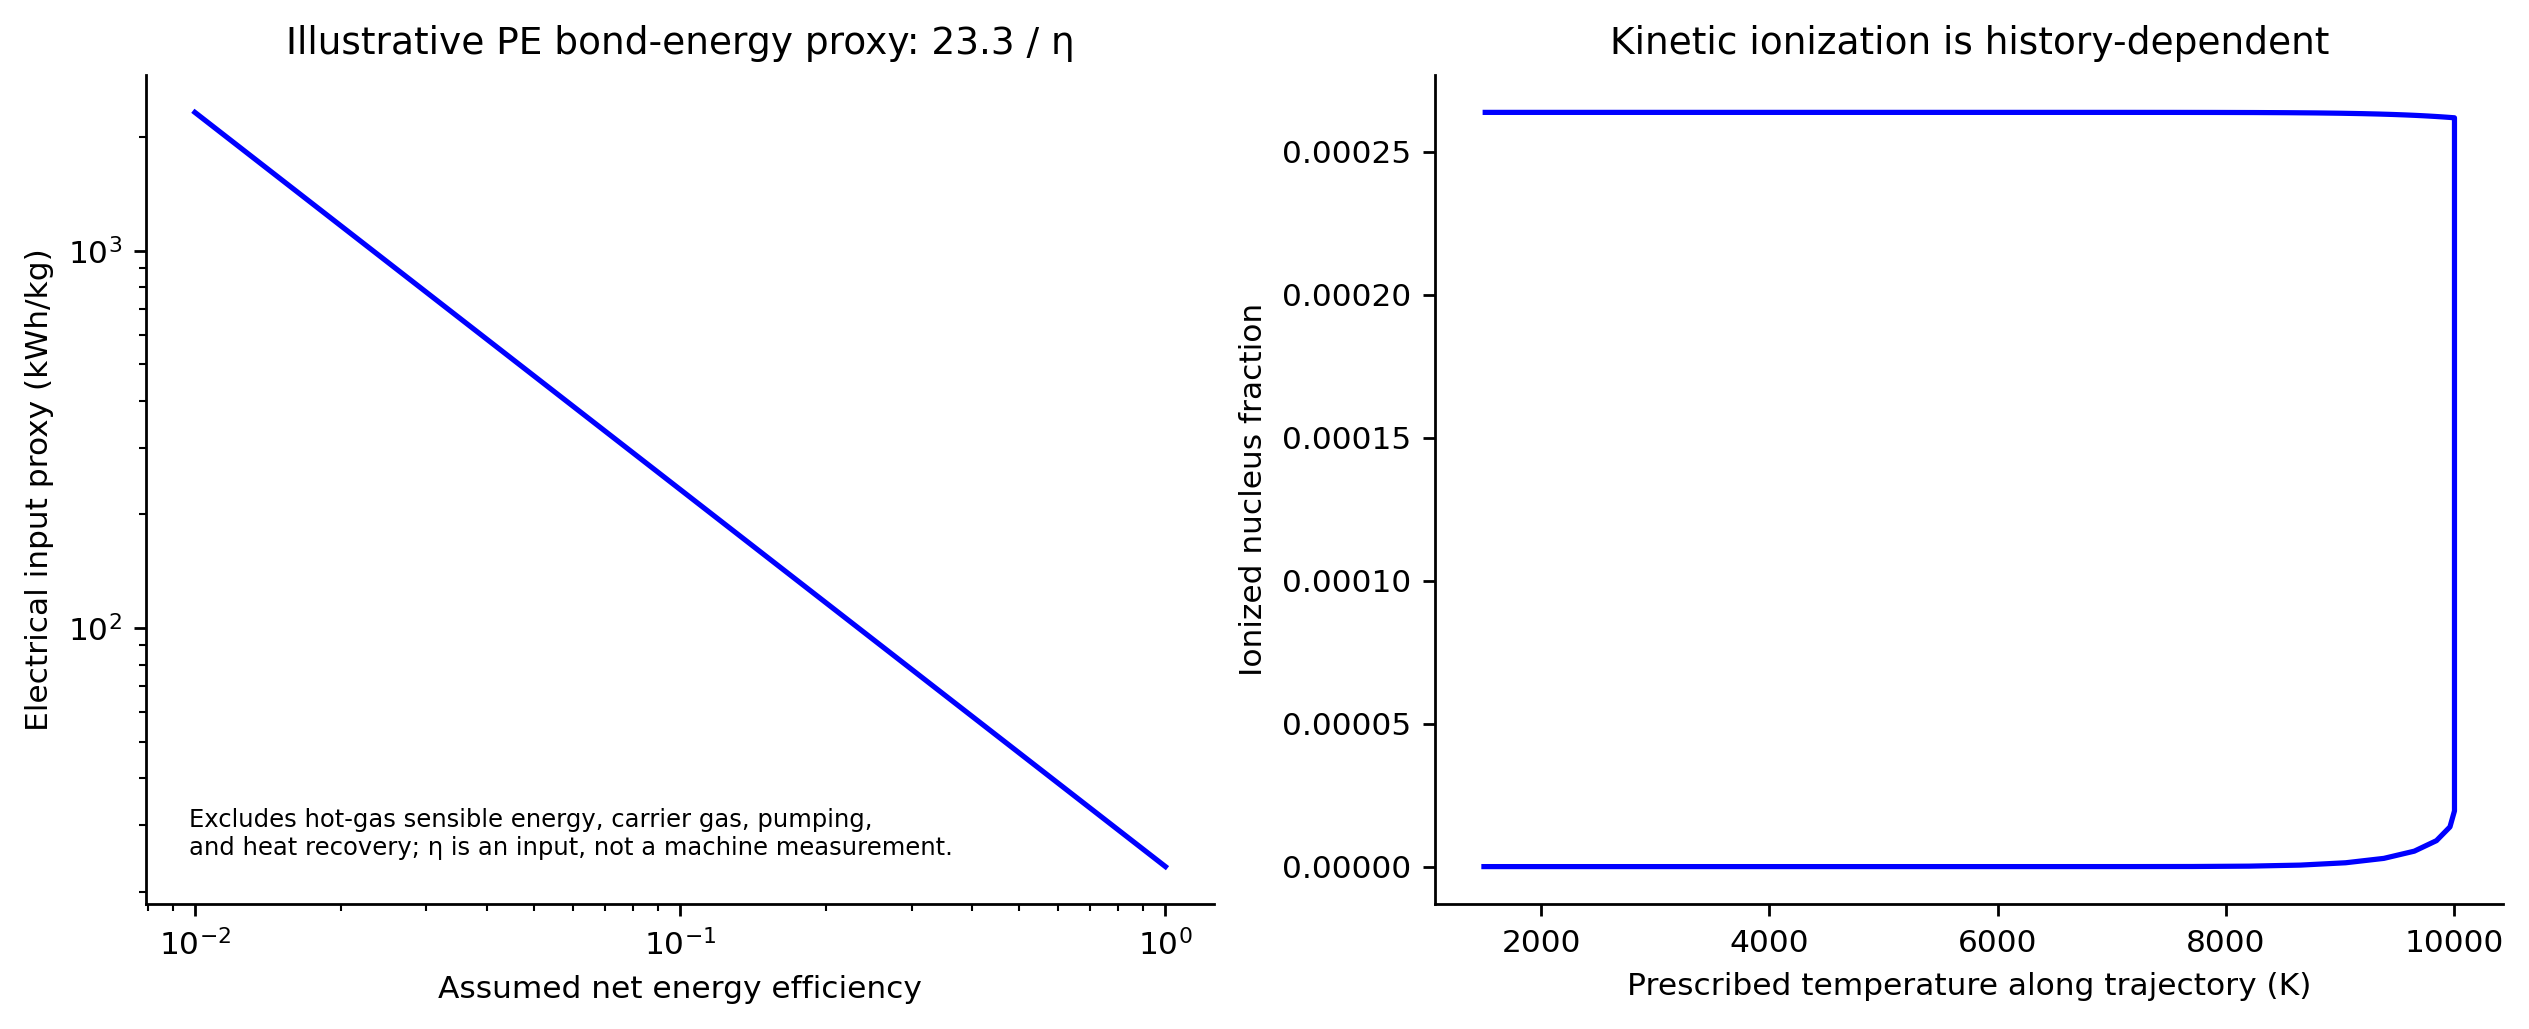

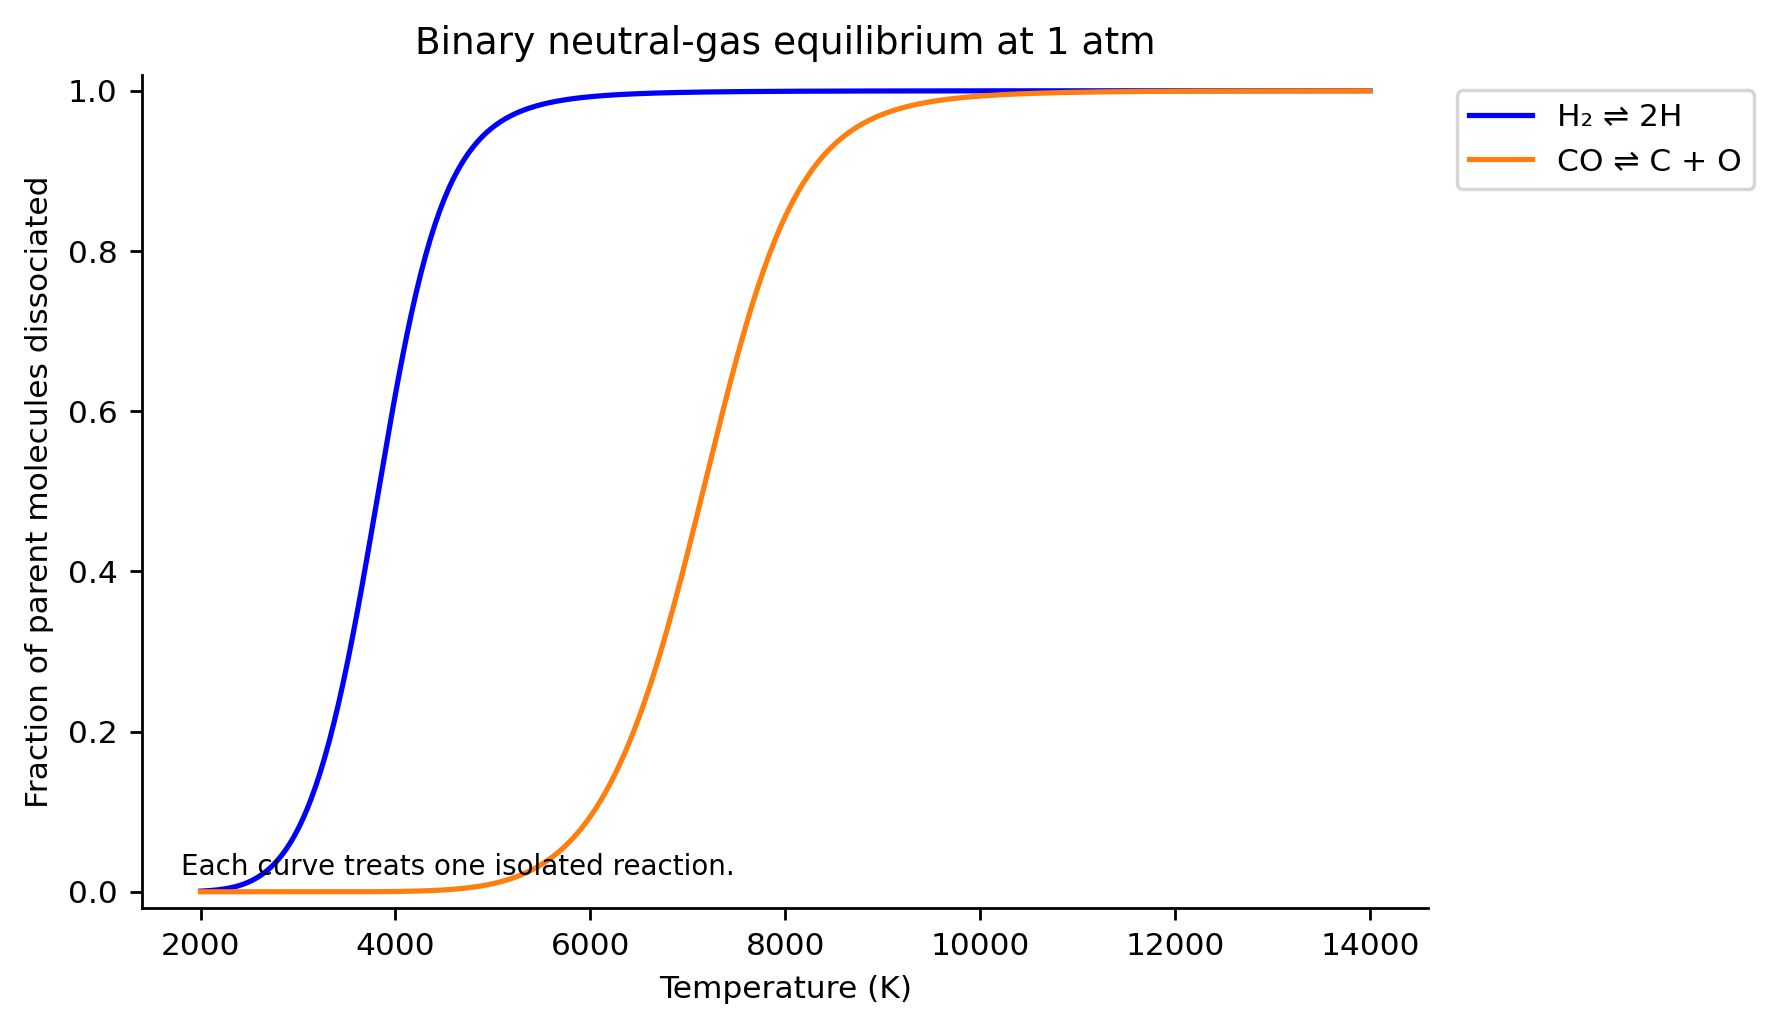

{
  "validation_passed": true,
  "baseline_peak_atomic": 0.9686447098103402,
  "baseline_final_atomic": 0.963193856421214,
  "performance": {
    "cpu_wall_s": 0.9909220209999603,
    "gpu_wall_s": 0.35949343300001146,
    "parcels": 256,
    "gpu_speedup_end_to_end": 2.7564398401678973
  },
  "results_archive": "atomization_results.zip"
}


In [5]:
"""Simulate post-vaporization C/H/O atomization with a conserved reaction graph.

The embedded NASA9 data supply ideal-gas thermochemistry. Finite-rate constants
are deliberately uncalibrated control inputs, not measured polymer kinetics.
No solid-particle heating, laser absorption, hydrodynamic PDE, soot population,
radiative association, ion extraction, or equipment-efficiency model is implied.

Numerical method: exact reversible edge flows, symmetric graph splitting, and
per-parcel adaptive step doubling in float64. CPU and CUDA share their numerical
source; independent SciPy BDF and constrained-equilibrium checks test that source.
"""

import argparse
import ctypes
import hashlib
import io
import itertools
import json
import math
import os
import shutil
import subprocess
import tempfile
import time
import zipfile
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from scipy import optimize, sparse
from scipy.integrate import solve_ivp

# - Control knobs ------------------------------------------------------------
CONTROLS = {
    "backend": "gpu",  # gpu requires CUDA; auto selects by batch size; cpu tests.
    "gpu_threshold": 128,
    "gpu_memory_fraction": 0.25,
    "max_batch": 2048,
    "cpu_threads": 4,
    "polymer": "PET",  # PE, PP, PS, PET, or custom elemental repeat counts.
    "custom_counts": [10.0, 8.0, 4.0],  # C, H, O; used for polymer='custom'.
    "initial_atomic_fraction": 0.0,
    "start_temperature_k": 1500.0,
    "peak_temperature_k": 10000.0,
    "floor_temperature_k": 1200.0,
    "heating_time_s": 2.0e-6,
    "hot_hold_time_s": 3.0e-6,
    "expansion_time_s": 3.0e-7,
    "expansion_duration_tau": 40.0,
    "effective_gamma": 1.30,
    "initial_nuclei_density_m3": 1.0e25,
    "background_pressure_pa": 1.0e-7,
    "local_collider_per_nucleus": 1.0,
    "carrier_per_nucleus": 0.0,
    "association_k3_m6_s": 1.0e-44,
    "rate_temperature_exponent": -1.0,
    "relative_tolerance": 2.0e-5,
    "absolute_tolerance": 2.0e-10,
    "max_attempts_per_parcel": 200000,
    "validation_abundance_tolerance": 2.0e-4,
    "thermo_table_points": 1601,
    "snapshots_per_phase": 24,
    "density_points": 24,
    "expansion_points": 24,
    "equilibrium_temperature_points": 70,
    "equilibrium_density_points": 64,
    "uncertainty_samples": 256,
    "rate_uncertainty_log10_sigma": 0.75,
    "density_range_m3": [1.0e22, 1.0e26],
    "expansion_range_s": [1.0e-8, 1.0e-4],
    "equilibrium_temperature_range_k": [1500.0, 14000.0],
    "seed": 1729,
    "benchmark_parcels": 256,
    "plot_dpi": 250,
    "show_plots": True,
    "output_directory": "atomization_results",
}

KB = 1.380649e-23
R_GAS = 8.31446261815324
P_STANDARD = 1.0e5
SPECIES = (
    "C",
    "H",
    "O",
    "H2",
    "O2",
    "CO",
    "C2",
    "C3",
    "CO2",
    "CH",
    "OH",
    "C+",
    "H+",
    "O+",
    "e-",
)
COUNTS = np.array(
    [
        [1, 0, 0],
        [0, 1, 0],
        [0, 0, 1],
        [0, 2, 0],
        [0, 0, 2],
        [1, 0, 1],
        [2, 0, 0],
        [3, 0, 0],
        [1, 0, 2],
        [1, 1, 0],
        [0, 1, 1],
        [1, 0, 0],
        [0, 1, 0],
        [0, 0, 1],
        [0, 0, 0],
    ],
    dtype=np.float64,
)
CHARGES = np.array([0] * 11 + [1, 1, 1, -1], dtype=np.float64)
# Each edge is parent <=> product_1 + product_2, with a prescribed collider M.
EDGES = np.array(
    [
        [3, 1, 1],
        [4, 2, 2],
        [5, 0, 2],
        [6, 0, 0],
        [7, 6, 0],
        [8, 5, 2],
        [9, 0, 1],
        [10, 2, 1],
        [0, 11, 14],
        [1, 12, 14],
        [2, 13, 14],
    ],
    dtype=np.int32,
)
N_SPECIES, N_REACTIONS = len(SPECIES), len(EDGES)
STOICH = np.zeros((N_SPECIES, N_REACTIONS), dtype=np.float64)
for _reaction, (_parent, _first, _second) in enumerate(EDGES):
    STOICH[_parent, _reaction] -= 1
    STOICH[_first, _reaction] += 1
    STOICH[_second, _reaction] += 1
STOICH_CSR = sparse.csr_matrix(STOICH)
ELEMENT_MASS_KG_MOL = np.array([0.0120107, 0.00100794, 0.0159994])
SOURCES = {
    "NASA9_report": "https://ntrs.nasa.gov/citations/20020085330",
    "NASA_CEA_data": "https://github.com/nasa/cea/blob/main/data/thermo.inp",
    "CuPy": "https://docs.cupy.dev/en/stable/user_guide/performance.html",
    "L4": "https://www.nvidia.com/en-us/data-center/l4/",
    "microplastic_ICP": "https://doi.org/10.1016/j.talanta.2020.121486",
    "vacuum_cluster_experiment": "https://doi.org/10.1103/PhysRevB.80.184113",
}
# Extracted without coefficient changes from NASA CEA thermo.inp, 2026-10-15.
# Per-species intervals: [300, 1000], [1000, 6000], [6000, 20000] K.
NASA_DATA = [
    [
        [
            649.503147,
            -0.964901086,
            2.504675479,
            -1.281448025e-05,
            1.980133654e-08,
            -1.606144025e-11,
            5.314483411e-15,
            85457.6311,
            4.747924288,
        ],
        [
            -128913.6472,
            171.9528572,
            2.646044387,
            -0.000335306895,
            1.74209274e-07,
            -2.902817829e-11,
            1.642182385e-15,
            84105.9785,
            4.130047418,
        ],
        [
            443252801.0,
            -288601.8412,
            77.3710832,
            -0.00971528189,
            6.64959533e-07,
            -2.230078776e-11,
            2.899388702e-16,
            2355273.444,
            -640.512316,
        ],
    ],
    [
        [0.0, 0.0, 2.5, 0.0, 0.0, 0.0, 0.0, 25473.70801, -0.446682853],
        [
            60.7877425,
            -0.1819354417,
            2.500211817,
            -1.226512864e-07,
            3.73287633e-11,
            -5.68774456e-15,
            3.410210197e-19,
            25474.86398,
            -0.448191777,
        ],
        [
            217375769.4,
            -131203.5403,
            33.991742,
            -0.00381399968,
            2.432854837e-07,
            -7.69427554e-12,
            9.64410563e-17,
            1067638.086,
            -274.2301051,
        ],
    ],
    [
        [
            -7953.6113,
            160.7177787,
            1.966226438,
            0.00101367031,
            -1.110415423e-06,
            6.5175075e-10,
            -1.584779251e-13,
            28403.62437,
            8.40424182,
        ],
        [
            261902.0262,
            -729.872203,
            3.31717727,
            -0.000428133436,
            1.036104594e-07,
            -9.43830433e-12,
            2.725038297e-16,
            33924.2806,
            -0.667958535,
        ],
        [
            177900426.4,
            -108232.8257,
            28.10778365,
            -0.002975232262,
            1.854997534e-07,
            -5.79623154e-12,
            7.191720164e-17,
            889094.263,
            -218.1728151,
        ],
    ],
    [
        [
            40783.2321,
            -800.918604,
            8.21470201,
            -0.01269714457,
            1.753605076e-05,
            -1.20286027e-08,
            3.36809349e-12,
            2682.484665,
            -30.43788844,
        ],
        [
            560812.801,
            -837.150474,
            2.975364532,
            0.001252249124,
            -3.74071619e-07,
            5.9366252e-11,
            -3.6069941e-15,
            5339.82441,
            -2.202774769,
        ],
        [
            496688412.0,
            -314754.7149,
            79.8412188,
            -0.00841478921,
            4.75324835e-07,
            -1.371873492e-11,
            1.605461756e-16,
            2488433.516,
            -669.572811,
        ],
    ],
    [
        [
            -34255.6342,
            484.700097,
            1.119010961,
            0.00429388924,
            -6.83630052e-07,
            -2.0233727e-09,
            1.039040018e-12,
            -3391.45487,
            18.4969947,
        ],
        [
            -1037939.022,
            2344.830282,
            1.819732036,
            0.001267847582,
            -2.188067988e-07,
            2.053719572e-11,
            -8.19346705e-16,
            -16890.10929,
            17.38716506,
        ],
        [
            497529430.0,
            -286610.6874,
            66.9035225,
            -0.00616995902,
            3.016396027e-07,
            -7.4214166e-12,
            7.27817577e-17,
            2293554.027,
            -553.062161,
        ],
    ],
    [
        [
            14890.45326,
            -292.2285939,
            5.72452717,
            -0.00817623503,
            1.456903469e-05,
            -1.087746302e-08,
            3.027941827e-12,
            -13031.31878,
            -7.85924135,
        ],
        [
            461919.725,
            -1944.704863,
            5.91671418,
            -0.000566428283,
            1.39881454e-07,
            -1.787680361e-11,
            9.62093557e-16,
            -2466.261084,
            -13.87413108,
        ],
        [
            886866296.0,
            -750037.784,
            249.5474979,
            -0.039563511,
            3.29777208e-06,
            -1.318409933e-10,
            1.998937948e-15,
            5701421.13,
            -2060.704786,
        ],
    ],
    [
        [
            555963.451,
            -9980.12644,
            66.8162037,
            -0.1743432724,
            0.0002448523051,
            -1.70346758e-07,
            4.68452773e-11,
            144586.9634,
            -344.82297,
        ],
        [
            -968926.793,
            3561.09299,
            -0.506413893,
            0.002945154879,
            -7.13944119e-07,
            8.67065725e-11,
            -4.07690681e-15,
            76817.9683,
            33.3998524,
        ],
        [
            6315145.92,
            13654.20661,
            -3.99690367,
            0.001937561376,
            -1.58444658e-07,
            5.52086166e-12,
            -7.25373534e-17,
            9387.02499,
            66.1432992,
        ],
    ],
    [
        [
            -43546.1448,
            666.018322,
            1.451033157,
            0.00743451312,
            -3.81015299e-06,
            -2.336961396e-11,
            4.40705453e-13,
            96351.702,
            20.25173297,
        ],
        [
            4508098.93,
            -14610.33761,
            22.81974644,
            -0.00854434061,
            2.146069341e-06,
            -2.103867761e-10,
            6.35158906e-15,
            191197.6065,
            -127.1869723,
        ],
        [
            153958985.9,
            -208905.7498,
            76.8111121,
            -0.00893905619,
            5.59403324e-07,
            -1.743774353e-11,
            2.181541208e-16,
            1650801.763,
            -608.169332,
        ],
    ],
    [
        [
            49436.5054,
            -626.411601,
            5.30172524,
            0.002503813816,
            -2.127308728e-07,
            -7.68998878e-10,
            2.849677801e-13,
            -45281.9846,
            -7.04827944,
        ],
        [
            117696.2419,
            -1788.791477,
            8.29152319,
            -9.22315678e-05,
            4.86367688e-09,
            -1.891053312e-12,
            6.33003659e-16,
            -39083.5059,
            -26.52669281,
        ],
        [
            -1544423287.0,
            1016847.056,
            -256.140523,
            0.0336940108,
            -2.181184337e-06,
            6.99142084e-11,
            -8.8423515e-16,
            -8043214.51,
            2254.177493,
        ],
    ],
    [
        [
            22205.90133,
            -340.541153,
            5.53145229,
            -0.00579496426,
            7.96955488e-06,
            -4.46591159e-09,
            9.59633832e-13,
            72407.8327,
            -9.10767305,
        ],
        [
            2060763.44,
            -5396.20666,
            7.85629385,
            -0.000796590745,
            1.764308305e-07,
            -1.976386267e-11,
            5.03042951e-16,
            106223.6592,
            -31.54757439,
        ],
        [
            -806836869.0,
            457545.054,
            -98.4397508,
            0.01235244098,
            -8.48560857e-07,
            3.040410624e-11,
            -4.40031517e-16,
            -3595851.59,
            895.347744,
        ],
    ],
    [
        [
            -1998.85899,
            93.0013616,
            3.050854229,
            0.001529529288,
            -3.157890998e-06,
            3.31544618e-09,
            -1.138762683e-12,
            2991.214235,
            4.67411079,
        ],
        [
            1017393.379,
            -2509.957276,
            5.11654786,
            0.000130529993,
            -8.28432226e-08,
            2.006475941e-11,
            -1.556993656e-15,
            20196.40206,
            -11.01282337,
        ],
        [
            284723419.3,
            -185953.2612,
            50.082409,
            -0.00514237498,
            2.875536589e-07,
            -8.22881796e-12,
            9.56722902e-17,
            1468393.908,
            -402.355558,
        ],
    ],
    [
        [
            2258.535929,
            -1.574575687,
            2.50363773,
            -5.20287837e-06,
            4.51690839e-09,
            -2.181431053e-12,
            4.495047033e-16,
            216895.1913,
            4.345699505,
        ],
        [
            12551.12551,
            -34.1187467,
            2.543383218,
            -2.805120849e-05,
            9.75164197e-09,
            -1.736855394e-12,
            1.246191931e-16,
            217100.1786,
            4.063913515,
        ],
        [
            561813.532,
            -6047.0589,
            5.88454147,
            -0.000721189453,
            6.82348411e-08,
            -2.59987859e-12,
            3.633868358e-17,
            258137.0458,
            -22.80019759,
        ],
    ],
    [
        [0.0, 0.0, 2.5, 0.0, 0.0, 0.0, 0.0, 184021.4877, -1.140646644],
        [0.0, 0.0, 2.5, 0.0, 0.0, 0.0, 0.0, 184021.4877, -1.140646644],
        [0.0, 0.0, 2.5, 0.0, 0.0, 0.0, 0.0, 184021.4877, -1.140646644],
    ],
    [
        [0.0, 0.0, 2.5, 0.0, 0.0, 0.0, 0.0, 187935.2842, 4.39337676],
        [
            -216651.3208,
            666.545615,
            1.702064364,
            0.000471499281,
            -1.427131823e-07,
            2.016595903e-11,
            -9.107157762e-16,
            183719.1966,
            10.05690382,
        ],
        [
            -214383538.3,
            146951.8523,
            -36.8086454,
            0.00503616454,
            -3.087873854e-07,
            9.18683487e-12,
            -1.074163268e-16,
            -961420.896,
            342.619308,
        ],
    ],
    [
        [0.0, 0.0, 2.5, 0.0, 0.0, 0.0, 0.0, -745.375, -11.72081224],
        [0.0, 0.0, 2.5, 0.0, 0.0, 0.0, 0.0, -745.375, -11.72081224],
        [0.0, 0.0, 2.5, 0.0, 0.0, 0.0, 0.0, -745.375, -11.72081224],
    ],
]
NASA_SOURCE_SHA256 = "fa7746572952d74e249e818a82a35c113829742fb421a308e167185528884363"


def thermochemistry(temperature_k):
    """Return species g/(RT), h/(RT), and cp/R from NASA9 coefficients.

    Args:
        temperature_k: Scalar or array of temperatures, strictly in 300-20000 K.

    Returns:
        Three arrays with shape temperature.shape + (number_of_species,).
    """
    temperature = np.asarray(temperature_k, dtype=np.float64)
    if (
        np.any(~np.isfinite(temperature))
        or np.any(temperature < 300.0)
        or np.any(temperature > 20000.0)
    ):
        raise ValueError("NASA9 evaluation requires finite 300-20000 K inputs.")
    interval = np.searchsorted([1000.0, 6000.0], temperature, side="right")
    coefficients = np.asarray(NASA_DATA)[np.arange(N_SPECIES), interval[..., None]]
    a = np.moveaxis(coefficients, -1, 0)
    t = temperature[..., None]
    cp = (
        a[0] / t**2
        + a[1] / t
        + a[2]
        + a[3] * t
        + a[4] * t**2
        + a[5] * t**3
        + a[6] * t**4
    )
    enthalpy = (
        -a[0] / t**2
        + a[1] * np.log(t) / t
        + a[2]
        + a[3] * t / 2
        + a[4] * t**2 / 3
        + a[5] * t**3 / 4
        + a[6] * t**4 / 5
        + a[7] / t
    )
    entropy = (
        -a[0] / (2 * t**2)
        - a[1] / t
        + a[2] * np.log(t)
        + a[3] * t
        + a[4] * t**2 / 2
        + a[5] * t**3 / 3
        + a[6] * t**4 / 4
        + a[8]
    )
    return enthalpy - entropy, enthalpy, cp


def elemental_fractions(config):
    """Return C/H/O nucleus fractions for the selected repeat-unit formula."""
    formulas = {
        "PE": [1, 2, 0],
        "PP": [3, 6, 0],
        "PS": [8, 8, 0],
        "PET": [10, 8, 4],
        "custom": config["custom_counts"],
    }
    counts = np.asarray(formulas[config["polymer"]], dtype=float)
    if counts.shape != (3,) or np.any(counts < 0) or counts.sum() <= 0:
        raise ValueError("Elemental counts must be three nonnegative numbers.")
    return counts / counts.sum()


def initial_composition(config):
    """Construct a conserved fragment-gas seed, not an intact polymer model."""
    fractions = elemental_fractions(config)
    fraction = config["initial_atomic_fraction"]
    y = np.zeros(N_SPECIES)
    y[:3] = fraction * fractions
    carbon, hydrogen, oxygen = (1 - fraction) * fractions
    carbon_monoxide = min(carbon, oxygen)
    y[5] = carbon_monoxide
    y[6] = (carbon - carbon_monoxide) / 2
    y[3] = hydrogen / 2
    y[4] = (oxygen - carbon_monoxide) / 2
    return y


def log_equilibrium_constants(temperature_k):
    """Return ln(Kc / [1 m^-3]) for each parent-to-two-products edge."""
    gibbs = thermochemistry(temperature_k)[0]
    return (
        -gibbs @ STOICH
        + np.log(P_STANDARD / (KB * np.asarray(temperature_k)))[..., None]
    )


def thermal_history(times, parameters, config):
    """Return prescribed T, nuclei density, and effective collider density.

    The nuclei density follows a homologously expanding parcel. The effective
    collider bath includes an independently controlled local plume contribution
    even when the chamber background pressure is zero. It is not a fluid solver.
    """
    density, tau, peak, pressure = parameters
    times = np.asarray(times)
    heat = config["heating_time_s"]
    release = heat + config["hot_hold_time_s"]
    heating = np.clip(times / heat, 0, 1)
    temperature = (
        config["start_temperature_k"]
        + (peak - config["start_temperature_k"]) * np.sin(np.pi * heating / 2) ** 2
    )
    scale = 1 + np.maximum(times - release, 0) / tau
    cooling = config["floor_temperature_k"] + (
        peak - config["floor_temperature_k"]
    ) * scale ** (-3 * (config["effective_gamma"] - 1))
    temperature = np.where(times > release, cooling, temperature)
    nuclei_density = density / scale**3
    collider_density = nuclei_density * (
        config["carrier_per_nucleus"] + config["local_collider_per_nucleus"]
    ) + pressure / (KB * temperature)
    return temperature, nuclei_density, collider_density


# - Shared C++ / CUDA numerical core -----------------------------------------
CORE = r"""
#define NS 15
#define NR 11
CONST int edge[33] = {EDGE_VALUES};
CONST double atoms[45] = {ATOM_VALUES};
DEV double bounded(double x, double lo, double hi) {
    return fmin(hi, fmax(lo, x));
}
DEV void gibbs_at(double t, const double* nasa, double* g) {
    int band = (t < 1000.0) ? 0 : ((t < 6000.0) ? 1 : 2);
    for (int i=0; i<NS; ++i) {
        const double* a = nasa + (i*3+band)*9;
        double h=-a[0]/(t*t)+a[1]*log(t)/t+a[2]+a[3]*t/2
            +a[4]*t*t/3+a[5]*t*t*t/4+a[6]*t*t*t*t/5+a[7]/t;
        double s=-a[0]/(2*t*t)-a[1]/t+a[2]*log(t)+a[3]*t
            +a[4]*t*t/2+a[5]*t*t*t/3+a[6]*t*t*t*t/4+a[8];
        g[i]=h-s;
    }
}
DEV void distribution(const double* lam, const double* g, double density,
    double t, const double* fractions, double* y, double* mass, double* h) {
    double offset=log(1e5/(1.380649e-23*t*density));
    for(int i=0;i<NS;++i) y[i]=0;
    for(int j=0;j<3;++j) {
        mass[j]=0;
        for(int k=0;k<3;++k) h[j*3+k]=0;
    }
    for(int i=0;i<11;++i) {
        double logy=offset-g[i]; bool allowed=true;
        for(int j=0;j<3;++j) {
            if(atoms[i*3+j]>0 && fractions[j]==0) allowed=false;
            logy+=atoms[i*3+j]*lam[j];
        }
        y[i]=allowed ? exp(bounded(logy,-740,500)) : 0;
        for(int j=0;j<3;++j) {
            mass[j]+=atoms[i*3+j]*y[i];
            for(int k=0;k<3;++k)
                h[j*3+k]+=atoms[i*3+j]*atoms[i*3+k]*y[i];
        }
    }
    double logw[3], largest=-1e300;
    for(int j=0;j<3;++j) {
        logw[j]=(fractions[j]>0) ? log(fmax(y[j],1e-320))
            +offset+g[j]-g[11+j]-g[14] : -1e300;
        largest=fmax(largest,logw[j]);
    }
    double sumw=0;
    for(int j=0;j<3;++j) sumw+=exp(logw[j]-largest);
    double loge=0.5*(largest+log(sumw));
    double totalion=0;
    for(int j=0;j<3;++j) {
        y[11+j]=(fractions[j]>0) ? exp(bounded(logw[j]-loge,-740,500)) : 0;
        totalion+=y[11+j]; mass[j]+=y[11+j];
        h[j*3+j]+=y[11+j];
    }
    y[14]=totalion;
    if(totalion>1e-290) for(int j=0;j<3;++j) for(int k=0;k<3;++k)
        h[j*3+k]-=0.5*y[11+j]*(y[11+k]/totalion);
}
DEV bool solve3(double* mat, double* rhs, double* answer) {
    for(int k=0;k<3;++k) {
        int pivot=k;
        for(int j=k+1;j<3;++j)
            if(fabs(mat[j*3+k])>fabs(mat[pivot*3+k])) pivot=j;
        if(fabs(mat[pivot*3+k])<1e-290) return false;
        for(int j=k;j<3;++j) {
            double tmp=mat[k*3+j]; mat[k*3+j]=mat[pivot*3+j];
            mat[pivot*3+j]=tmp;
        }
        double tmp=rhs[k]; rhs[k]=rhs[pivot]; rhs[pivot]=tmp;
        for(int j=k+1;j<3;++j) {
            double fac=mat[j*3+k]/mat[k*3+k];
            for(int m=k;m<3;++m) mat[j*3+m]-=fac*mat[k*3+m];
            rhs[j]-=fac*rhs[k];
        }
    }
    for(int j=2;j>=0;--j) {
        double value=rhs[j];
        for(int k=j+1;k<3;++k) value-=mat[j*3+k]*answer[k];
        answer[j]=value/mat[j*3+j];
    }
    return true;
}
DEV void equilibrium_one(double t, double density, const double* nasa,
    const double* frac, double* out, double* diagnostics) {
    double g[NS], lam[3], mass[3], h[9], rhs[3], delta[3], y[NS];
    gibbs_at(t,nasa,g);
    for(int j=0;j<3;++j) lam[j]=(frac[j]>0) ?
        g[j]+log(frac[j]*density*1.380649e-23*t/1e5) : 0;
    double error=1e300; int iteration=0; int status=1;
    for(iteration=0;iteration<160;++iteration) {
        distribution(lam,g,density,t,frac,y,mass,h); error=0;
        for(int j=0;j<3;++j) {
            rhs[j]=(frac[j]>0) ? log(mass[j]/frac[j]) : 0;
            error=fmax(error,fabs(rhs[j]));
            for(int k=0;k<3;++k)
                h[j*3+k]=(frac[j]>0) ? h[j*3+k]/mass[j] : (j==k ? 1:0);
        }
        if(error<2e-10) {status=0;break;}
        if(!solve3(h,rhs,delta)) {status=2;break;}
        double largest=0;
        for(int j=0;j<3;++j) largest=fmax(largest,fabs(delta[j]));
        double step=fmin(1.0,20.0/fmax(largest,1e-100));
        bool accepted=false;
        for(int trial=0;trial<30;++trial) {
            double next[3], yy[NS], mm[3], hh[9], err=0;
            for(int j=0;j<3;++j) next[j]=lam[j]-step*delta[j];
            distribution(next,g,density,t,frac,yy,mm,hh);
            for(int j=0;j<3;++j) if(frac[j]>0)
                err=fmax(err,fabs(log(mm[j]/frac[j])));
            if(err<error || err<2e-10) {
                for(int j=0;j<3;++j) lam[j]=next[j];
                accepted=true;break;
            }
            step*=0.5;
        }
        if(!accepted) {status=3;break;}
    }
    distribution(lam,g,density,t,frac,out,mass,h);
    diagnostics[0]=status; diagnostics[1]=error; diagnostics[2]=iteration;
}
DEV void environment(double time, const double* p, const double* cfg,
    double* temperature, double* nb, double* collider) {
    double release=cfg[2]+cfg[3];
    if(time<=cfg[2]) {
        double s=sin(1.5707963267948966*time/cfg[2]);
        *temperature=cfg[0]+(p[2]-cfg[0])*s*s;
    } else *temperature=p[2];
    double scale=1+fmax(time-release,0.0)/p[1];
    if(time>release) *temperature=cfg[1]+(p[2]-cfg[1])
        *pow(scale,-3*(cfg[4]-1));
    *nb=p[0]/(scale*scale*scale);
    *collider=*nb*cfg[5]+p[3]/(1.380649e-23*(*temperature));
}
DEV void graph_flow(double* y,double start,double dt,const double* p,
    const double* cfg,const double* k3,const double* table,int nt,
    double loglo,double dlog) {
    double t,nb,collider;
    environment(start+0.5*dt,p,cfg,&t,&nb,&collider);
    double coordinate=bounded((log(t)-loglo)/dlog,0,nt-1.000000001);
    int lower=(int)coordinate; double weight=coordinate-lower;
    double reaction_bath=nb*collider*pow(t/3000.0,cfg[6]);
    for(int phase=0;phase<2;++phase) for(int pos=0;pos<NR;++pos) {
        int r=(phase==0) ? pos : NR-1-pos;
        int parent=edge[3*r], first=edge[3*r+1], second=edge[3*r+2];
        double logkc=(1-weight)*table[lower*NR+r]+weight*table[(lower+1)*NR+r];
        double kappa=exp(logkc-log(nb));
        double a=y[parent],b=y[first],c=y[second];
        bool same=(first==second);
        double constant=kappa*a-b*c;
        double linear=kappa+(same ? 4*b : b+c);
        double disc=same ? sqrt(kappa*(kappa+8*b+16*a)) :
            sqrt((b-c)*(b-c)+kappa*(kappa+2*(b+c)+4*a));
        double bh=0.5*dt*k3[r]*reaction_bath;
        double phi=(disc>1e-200) ? -expm1(-disc*bh)/disc : bh;
        double extent=2*constant*phi/(2+(linear-disc)*phi);
        double low=same ? -b/2 : -fmin(b,c);
        extent=bounded(extent,low,a);
        y[parent]-=extent; y[first]+=extent; y[second]+=extent;
    }
}
DEV void integrate_one(const double* p,const double* cfg,const double* k3,
    const double* table,int nt,double loglo,double dlog,const double* initial,
    const double* sample,int nsample,double* output,double* diagnostics) {
    double y[NS],coarse[NS],fine[NS];
    for(int i=0;i<NS;++i) y[i]=initial[i];
    double current=0,dt=fmin(cfg[2],p[1])*0.02,previous_dt=dt;
    int attempts=0,rejected=0,accepted=0,status=0;
    for(int snap=0;snap<nsample;++snap) {
        double target=sample[snap];
        while(current<target) {
            if(attempts++>=(int)cfg[9]) {status=1;break;}
            dt=fmin(dt,target-current);
            double cap=current<cfg[2]+cfg[3] ? fmin(cfg[2],cfg[3]) :
                p[1]+current-cfg[2]-cfg[3];
            dt=fmin(dt,0.25*cap);
            if(dt<=1e-18*fmax(1e-6,target)) {status=2;break;}
            for(int i=0;i<NS;++i) coarse[i]=fine[i]=y[i];
            graph_flow(coarse,current,dt,p,cfg,k3,table,nt,loglo,dlog);
            graph_flow(fine,current,dt/2,p,cfg,k3,table,nt,loglo,dlog);
            graph_flow(fine,current+dt/2,dt/2,p,cfg,k3,table,nt,loglo,dlog);
            double err=0;
            for(int i=0;i<NS;++i) err=fmax(err,fabs(fine[i]-coarse[i])/
                (3*(cfg[8]+cfg[7]*fmax(fabs(fine[i]),fabs(y[i])))));
            if(!isfinite(err)) {status=3;break;}
            if(err<=1) {
                for(int i=0;i<NS;++i) y[i]=fine[i];
                current+=dt; accepted++; previous_dt=dt;
                if(target-current<2e-15*fmax(target,1e-10)) current=target;
            } else rejected++;
            double factor=(err>1e-20) ? bounded(0.9*pow(err,-1.0/3),0.2,2.5):2.5;
            dt*=factor;
        }
        for(int i=0;i<NS;++i) output[snap*NS+i]=(status==0) ? y[i] : nan("");
        if(status) break;
        // Restore a useful step after landing on a narrowly spaced snapshot.
        dt=fmax(dt,previous_dt*0.5);
    }
    diagnostics[0]=status;diagnostics[1]=accepted;
    diagnostics[2]=rejected;diagnostics[3]=current;
}
"""
CORE = CORE.replace("EDGE_VALUES", ",".join(map(str, EDGES.ravel())))
CORE = CORE.replace("ATOM_VALUES", ",".join(map(str, COUNTS.ravel())))

CPU_WRAPPER = r"""
extern "C" void equilibrium_batch(int n,const double* t,const double* density,
 const double* nasa,const double* frac,double* out,double* diagnostic) {
 #pragma omp parallel for schedule(dynamic,16)
 for(int k=0;k<n;++k) equilibrium_one(t[k],density[k],nasa,frac,
     out+k*NS,diagnostic+k*3);
}
extern "C" void integrate_batch(int n,const double* parameters,const double* cfg,
 const double* k3,const double* table,int nt,double loglo,double dlog,
 const double* initial,const double* sample,int nsample,double* out,double* diag) {
 #pragma omp parallel for schedule(dynamic,4)
 for(int k=0;k<n;++k) integrate_one(parameters+k*4,cfg,k3+k*NR,table,nt,loglo,
     dlog,initial,sample+k*nsample,nsample,out+k*nsample*NS,diag+k*4);
}
"""
GPU_WRAPPER = r"""
extern "C" __global__ void equilibrium_batch(int n,const double* t,
 const double* density,const double* nasa,const double* frac,double* out,
 double* diagnostic) {
 int k=blockDim.x*blockIdx.x+threadIdx.x;
 if(k<n) equilibrium_one(t[k],density[k],nasa,frac,out+k*NS,diagnostic+k*3);
}
extern "C" __global__ void integrate_batch(int n,const double* parameters,
 const double* cfg,const double* k3,const double* table,int nt,double loglo,
 double dlog,const double* initial,const double* sample,int nsample,
 double* out,double* diag) {
 int k=blockDim.x*blockIdx.x+threadIdx.x;
 if(k<n) integrate_one(parameters+k*4,cfg,k3+k*NR,table,nt,loglo,dlog,initial,
     sample+k*nsample,nsample,out+k*nsample*NS,diag+k*4);
}
"""


class Engine:
    """Run the reaction adjacency kernel on CUDA or a compiled CPU reference."""

    def __init__(self, config):
        """Detect devices and initialize float64 execution backends."""
        self.config = config
        self.cp = None
        self.gpu_module = None
        self.cpu_library = None
        self.device = {"available": False}
        if config["backend"] != "cpu":
            try:
                import cupy as cp

                cp.zeros(1).sum().item()
                free, total = cp.cuda.runtime.memGetInfo()
                properties = cp.cuda.runtime.getDeviceProperties(0)
                name = properties["name"]
                if isinstance(name, bytes):
                    name = name.decode()
                self.device = {
                    "available": True,
                    "name": name,
                    "free_bytes": free,
                    "total_bytes": total,
                }
                self.cp = cp
            except Exception as error:
                self.device["error"] = str(error)
                if config["backend"] == "gpu":
                    raise RuntimeError(
                        "CUDA is required by backend='gpu'. Select a Colab GPU "
                        "runtime and install one matching CuPy wheel. Use "
                        "backend='cpu' only for CPU verification."
                    ) from error
        self.last_backend = None

    def _cpu(self):
        """Compile the shared graph algorithm without CUDA or fast-math."""
        if self.cpu_library is None:
            compiler = shutil.which("g++")
            if compiler is None:
                raise RuntimeError(
                    "The CPU reference requires g++ (Colab supplies it)."
                )
            text = (
                "#include <cmath>\n#define DEV inline\n#define CONST const\n"
                "using std::isfinite;\n" + CORE + CPU_WRAPPER
            )
            digest = hashlib.sha256(text.encode()).hexdigest()[:16]
            root = Path(tempfile.gettempdir()) / "atomization_cpp_cache"
            root.mkdir(exist_ok=True)
            source, library = root / f"core_{digest}.cpp", root / f"core_{digest}.so"
            if not library.exists():
                source.write_text(text)
                subprocess.run(
                    [
                        compiler,
                        "-O3",
                        "-std=c++17",
                        "-shared",
                        "-fPIC",
                        "-fopenmp",
                        str(source),
                        "-o",
                        str(library),
                    ],
                    check=True,
                    capture_output=True,
                    text=True,
                )
            self.cpu_library = ctypes.CDLL(str(library))
            self.cpu_library.omp_set_num_threads.argtypes = [ctypes.c_int]
            self.cpu_library.omp_set_num_threads(self.config["cpu_threads"])
            pointer = np.ctypeslib.ndpointer(dtype=np.float64, flags="C_CONTIGUOUS")
            self.cpu_library.equilibrium_batch.argtypes = [
                ctypes.c_int,
                pointer,
                pointer,
                pointer,
                pointer,
                pointer,
                pointer,
            ]
            self.cpu_library.equilibrium_batch.restype = None
            self.cpu_library.integrate_batch.argtypes = [
                ctypes.c_int,
                pointer,
                pointer,
                pointer,
                pointer,
                ctypes.c_int,
                ctypes.c_double,
                ctypes.c_double,
                pointer,
                pointer,
                ctypes.c_int,
                pointer,
                pointer,
            ]
            self.cpu_library.integrate_batch.restype = None
        return self.cpu_library

    def _gpu(self):
        """Compile an on-device, one-thread-per-parcel adjacency integrator."""
        if self.gpu_module is None:
            source = (
                "#define DEV __device__ inline\n"
                "#define CONST __device__ __constant__\n" + CORE + GPU_WRAPPER
            )
            self.gpu_module = self.cp.RawModule(
                code=source,
                options=("--std=c++17",),
                name_expressions=("equilibrium_batch", "integrate_batch"),
            )
        return self.gpu_module

    def _use_gpu(self, size, force=None):
        """Route by batch size without changing tolerances or graph edges."""
        if force is not None:
            if force == "gpu" and self.cp is None:
                raise RuntimeError("A GPU comparison was requested without CUDA.")
            return force == "gpu"
        return self.cp is not None and (
            self.config["backend"] == "gpu" or size >= self.config["gpu_threshold"]
        )

    def _execute(self, name, arguments, output_shapes, use_gpu):
        """Execute a batch and return host arrays after explicit synchronization."""
        n = int(arguments[0])
        if not use_gpu:
            self.last_backend = "cpu"
            outputs = [np.full(shape, np.nan) for shape in output_shapes]
            function = getattr(self._cpu(), name)
            function(*arguments, *outputs)
            return outputs
        self.last_backend = "gpu"
        cp = self.cp
        converted = [
            cp.asarray(item) if isinstance(item, np.ndarray) else item
            for item in arguments
        ]
        outputs = [cp.full(shape, cp.nan, dtype=cp.float64) for shape in output_shapes]
        function = self._gpu().get_function(name)
        function(((n + 63) // 64,), (64,), tuple(converted + outputs))
        cp.cuda.get_current_stream().synchronize()
        return [cp.asnumpy(item) for item in outputs]

    def equilibrium(self, temperatures, densities, force=None):
        """Compute restricted ideal-gas equilibrium, including first ionization."""
        temperatures, densities = np.broadcast_arrays(temperatures, densities)
        thermochemistry(temperatures)  # Domain check; never extrapolate.
        if np.any(densities <= 0):
            raise ValueError("Nuclei densities must be positive.")
        shape = temperatures.shape
        n = temperatures.size
        arguments = [
            np.int32(n),
            np.ascontiguousarray(temperatures.ravel(), dtype=np.float64),
            np.ascontiguousarray(densities.ravel(), dtype=np.float64),
            np.ascontiguousarray(NASA_DATA, dtype=float),
            np.ascontiguousarray(elemental_fractions(self.config)),
        ]
        output, diagnostic = self._execute(
            "equilibrium_batch",
            arguments,
            [(n, N_SPECIES), (n, 3)],
            self._use_gpu(n, force),
        )
        if np.any(diagnostic[:, 0] != 0) or not np.isfinite(output).all():
            bad = np.flatnonzero(diagnostic[:, 0] != 0)
            raise RuntimeError(f"Equilibrium failed for cases {bad[:10].tolist()}.")
        return output.reshape(shape + (N_SPECIES,)), diagnostic.reshape(shape + (3,))

    def integrate(self, parameters, rate_multipliers=None, config=None, force=None):
        """Integrate independent parcels in memory-sized, adaptive batches."""
        cfg = dict(self.config if config is None else config)
        parameters = np.ascontiguousarray(np.atleast_2d(parameters), dtype=float)
        n = len(parameters)
        if parameters.shape[1] != 4 or not np.isfinite(parameters).all():
            raise ValueError("Each parcel needs finite [density, tau, peak, pressure].")
        if np.any(parameters[:, :2] <= 0) or np.any(parameters[:, 3] < 0):
            raise ValueError(
                "Positive density/tau and nonnegative pressure are required."
            )
        thermochemistry(parameters[:, 2])
        if np.any(
            parameters[:, 2]
            < max(cfg["start_temperature_k"], cfg["floor_temperature_k"])
        ):
            raise ValueError("Peak temperature must exceed the start and floor.")
        rates = (
            np.ones((n, N_REACTIONS))
            if rate_multipliers is None
            else np.broadcast_to(rate_multipliers, (n, N_REACTIONS)).copy()
        )
        if not np.isfinite(rates).all() or np.any(rates <= 0):
            raise ValueError("Rate multipliers must be positive and finite.")
        rates = np.ascontiguousarray(rates * cfg["association_k3_m6_s"])
        lower = min(cfg["start_temperature_k"], cfg["floor_temperature_k"])
        upper = max(float(parameters[:, 2].max()), lower * (1 + 1e-8))
        table_t = np.geomspace(lower, upper, cfg["thermo_table_points"])
        table = np.ascontiguousarray(log_equilibrium_constants(table_t))
        loglo, dlog = math.log(lower), math.log(upper / lower) / (len(table_t) - 1)
        packed = np.array(
            [
                cfg["start_temperature_k"],
                cfg["floor_temperature_k"],
                cfg["heating_time_s"],
                cfg["hot_hold_time_s"],
                cfg["effective_gamma"],
                cfg["carrier_per_nucleus"] + cfg["local_collider_per_nucleus"],
                cfg["rate_temperature_exponent"],
                cfg["relative_tolerance"],
                cfg["absolute_tolerance"],
                cfg["max_attempts_per_parcel"],
            ],
            dtype=float,
        )
        sample = sample_times(parameters[:, 1], cfg)
        nsample = sample.shape[1]
        initial = np.ascontiguousarray(initial_composition(cfg))
        use_gpu = self._use_gpu(n, force)
        batch = cfg["max_batch"]
        if use_gpu:
            free, _ = self.cp.cuda.runtime.memGetInfo()
            bytes_per_parcel = 8 * (
                nsample * N_SPECIES + nsample + 4 + N_REACTIONS + 512
            )
            batch = min(
                batch, max(1, int(free * cfg["gpu_memory_fraction"] / bytes_per_parcel))
            )
        output = np.empty((n, nsample, N_SPECIES))
        diagnostic = np.empty((n, 4))
        for start in range(0, n, batch):
            stop = min(n, start + batch)
            arguments = [
                np.int32(stop - start),
                parameters[start:stop],
                packed,
                rates[start:stop],
                table,
                np.int32(len(table_t)),
                np.float64(loglo),
                np.float64(dlog),
                initial,
                np.ascontiguousarray(sample[start:stop]),
                np.int32(nsample),
            ]
            output[start:stop], diagnostic[start:stop] = self._execute(
                "integrate_batch",
                arguments,
                [(stop - start, nsample, N_SPECIES), (stop - start, 4)],
                use_gpu,
            )
        if np.any(diagnostic[:, 0] != 0) or not np.isfinite(output).all():
            failures = np.flatnonzero(diagnostic[:, 0] != 0)
            raise RuntimeError(
                f"Integration failed for cases {failures[:10].tolist()}; "
                "increase max_attempts or inspect the input regime."
            )
        return output, sample, diagnostic


def sample_times(expansion_times, config):
    """Return phase-aligned snapshots, with exact heating/release boundaries."""
    count = config["snapshots_per_phase"]
    heat, hold = config["heating_time_s"], config["hot_hold_time_s"]
    pre = np.r_[np.linspace(0, heat, count), np.linspace(heat, heat + hold, count)[1:]]
    post = np.geomspace(1.0e-3, config["expansion_duration_tau"], 2 * count)
    return np.concatenate(
        [
            np.broadcast_to(pre, (len(expansion_times), len(pre))),
            heat + hold + np.asarray(expansion_times)[:, None] * post,
        ],
        axis=1,
    ).copy()


def composition_metrics(composition):
    """Return nucleus-weighted monatomic, ionic, and small-carbon fractions."""
    y = np.asarray(composition)
    return {
        "atomic": y[..., :3].sum(axis=-1) + y[..., 11:14].sum(axis=-1),
        "neutral_atomic": y[..., :3].sum(axis=-1),
        "ionic": y[..., 11:14].sum(axis=-1),
        "carbon_small": 2 * y[..., 6] + 3 * y[..., 7],
    }


def conservation_error(composition, config):
    """Measure absolute nucleus-fraction and charge-fraction conservation errors."""
    y = np.asarray(composition)
    return {
        "element_max_abs": float(
            np.max(np.abs(y @ COUNTS - elemental_fractions(config)))
        ),
        "charge_max_abs": float(np.max(np.abs(y @ CHARGES))),
        "minimum_abundance": float(y.min()),
    }


def validate_config(config):
    """Reject invalid controls before allocating a model or launching CUDA."""
    if config["backend"] not in {"cpu", "auto", "gpu"}:
        raise ValueError("backend must be cpu, auto, or gpu.")
    elemental_fractions(config)
    if not 0 <= config["initial_atomic_fraction"] <= 1:
        raise ValueError("initial_atomic_fraction must lie in [0, 1].")
    positive = [
        "max_batch",
        "association_k3_m6_s",
        "relative_tolerance",
        "absolute_tolerance",
        "heating_time_s",
        "hot_hold_time_s",
        "expansion_time_s",
        "expansion_duration_tau",
    ]
    if any(config[key] <= 0 for key in positive):
        raise ValueError(
            "Positive times, rates, batch sizes, and tolerances are required."
        )
    if not 0 < config["gpu_memory_fraction"] < 0.8:
        raise ValueError("gpu_memory_fraction must lie between 0 and 0.8.")
    if config["effective_gamma"] <= 1:
        raise ValueError(
            "effective_gamma must exceed 1 for prescribed expansion cooling."
        )
    if min(config["carrier_per_nucleus"], config["local_collider_per_nucleus"]) < 0:
        raise ValueError("Collider contributions must be nonnegative.")
    for key in [
        "thermo_table_points",
        "snapshots_per_phase",
        "density_points",
        "expansion_points",
        "equilibrium_temperature_points",
        "equilibrium_density_points",
        "uncertainty_samples",
    ]:
        if int(config[key]) != config[key] or config[key] < 3:
            raise ValueError(f"{key} must be an integer of at least 3.")
    for key in [
        "density_range_m3",
        "expansion_range_s",
        "equilibrium_temperature_range_k",
    ]:
        low, high = config[key]
        if not 0 < low < high:
            raise ValueError(f"Invalid increasing positive interval: {key}")
    thermochemistry(
        [
            config["start_temperature_k"],
            config["floor_temperature_k"],
            config["peak_temperature_k"],
            *config["equilibrium_temperature_range_k"],
        ]
    )


def independent_rhs(time_s, y, parameters, config, multipliers=None):
    """Evaluate the unsplit mass-action ODE with exact NASA9 thermochemistry."""
    temperature, density, collider = thermal_history(time_s, parameters, config)
    k3 = (
        config["association_k3_m6_s"]
        * (temperature / 3000) ** config["rate_temperature_exponent"]
    )
    if multipliers is not None:
        k3 = k3 * multipliers
    parent, first, second = EDGES.T
    flux = (
        k3
        * collider
        * density
        * (
            np.exp(log_equilibrium_constants(temperature)) / density * y[parent]
            - y[first] * y[second]
        )
    )
    return STOICH_CSR @ flux


def validate_numerics(engine, config, parameters):
    """Check conservation, step refinement, table refinement, and a BDF reference."""
    check = dict(config)
    check["snapshots_per_phase"] = 10
    parameters = np.atleast_2d(parameters)
    baseline, times, _ = engine.integrate(parameters, config=check)
    tight = dict(check)
    tight["relative_tolerance"] /= 4
    tight["absolute_tolerance"] /= 4
    refined, _, _ = engine.integrate(parameters, config=tight)
    finer_table = dict(tight)
    finer_table["thermo_table_points"] = 2 * config["thermo_table_points"] - 1
    table_result, _, _ = engine.integrate(parameters, config=finer_table)
    reports = {
        "conservation": conservation_error(refined, config),
        "step_refinement_max_abs": float(np.max(np.abs(baseline - refined))),
        "table_refinement_max_abs": float(np.max(np.abs(refined - table_result))),
    }
    # Integrate the same physical ODE without graph splitting or Kc tables.
    p = parameters[0]
    release = check["heating_time_s"] + check["hot_hold_time_s"]
    boundaries = [0, check["heating_time_s"], release, times[0, -1]]
    current = initial_composition(check)
    dense_solutions = []
    for start, stop in itertools.pairwise(boundaries):
        solution = solve_ivp(
            lambda t, y: independent_rhs(t, y, p, check),
            (start, stop),
            current,
            method="BDF",
            rtol=2e-8,
            atol=2e-12,
            dense_output=True,
            max_step=(stop - start) / 80,
        )
        if not solution.success:
            raise RuntimeError(f"Independent BDF failed: {solution.message}")
        dense_solutions.append(solution.sol)
        current = solution.y[:, -1]
    bdf = np.empty_like(refined[0])
    for index, moment in enumerate(times[0]):
        phase = min(np.searchsorted(boundaries[1:], moment, side="right"), 2)
        bdf[index] = dense_solutions[phase](moment)
    reports["independent_bdf_max_abs"] = float(np.max(np.abs(bdf - table_result[0])))
    reports["independent_bdf_final_atomic_abs"] = float(
        abs(
            composition_metrics(bdf)["atomic"][-1]
            - composition_metrics(table_result[0])["atomic"][-1]
        )
    )
    # A different constrained optimizer verifies a selected equilibrium solution.
    eq_t = max(3500.0, min(config["peak_temperature_k"], 6000.0))
    eq_n = config["initial_nuclei_density_m3"]
    eq, _ = engine.equilibrium(np.array([eq_t]), np.array([eq_n]))
    fractions = elemental_fractions(config)
    active = np.flatnonzero(np.all((COUNTS == 0) | (fractions > 0), axis=1))
    constraints = np.vstack([COUNTS[active].T[fractions > 0], CHARGES[active]])
    target = np.r_[fractions[fractions > 0], 0.0]
    g = thermochemistry(eq_t)[0][active]
    offset = math.log(eq_n * KB * eq_t / P_STANDARD)

    def objective(z):
        """Evaluate the dimensionless Helmholtz free energy at fixed T and V."""
        return float(np.sum(z * (g + np.log(np.maximum(z, 1e-300)) + offset - 1)))

    def jacobian(z):
        """Return the objective gradient for a second equilibrium implementation."""
        return g + np.log(np.maximum(z, 1e-300)) + offset

    # Perturb a feasible equilibrium point along a conserved reaction direction.
    seed = eq[0, active].copy()
    direction = STOICH[active, 0]
    maximum = min(
        [seed[i] / -direction[i] for i in range(len(seed)) if direction[i] < 0] or [0]
    )
    seed += 0.05 * maximum * direction
    result = optimize.minimize(
        objective,
        seed,
        jac=jacobian,
        method="SLSQP",
        bounds=[(1e-28, None)] * len(active),
        constraints=[
            {
                "type": "eq",
                "fun": lambda z: constraints @ z - target,
                "jac": lambda z: constraints,
            }
        ],
        options={"ftol": 1e-14, "maxiter": 4000},
    )
    reports["equilibrium_optimizer_success"] = bool(result.success)
    reports["equilibrium_optimizer_max_abs"] = float(
        np.max(np.abs(result.x - eq[0, active]))
    )
    reports["equilibrium_conservation"] = conservation_error(eq, config)
    # Detailed balance is also tested against every represented reversible edge.
    parent, first, second = EDGES.T
    active_edges = (
        (eq[0, parent] > 1e-100) & (eq[0, first] > 1e-100) & (eq[0, second] > 1e-100)
    )
    balance = (
        np.log(eq[0, first][active_edges])
        + np.log(eq[0, second][active_edges])
        - np.log(eq[0, parent][active_edges])
        - log_equilibrium_constants(eq_t)[active_edges]
        + math.log(eq_n)
    )
    reports["equilibrium_log_balance_max_abs"] = float(np.max(np.abs(balance)))
    if engine.cp is not None:
        cpu, _, _ = engine.integrate(parameters, config=tight, force="cpu")
        gpu, _, _ = engine.integrate(parameters, config=tight, force="gpu")
        reports["cpu_gpu_max_abs"] = float(np.max(np.abs(cpu - gpu)))
    else:
        reports["cpu_gpu_max_abs"] = None
    reports["pass"] = bool(
        reports["conservation"]["element_max_abs"] < 1e-9
        and reports["conservation"]["charge_max_abs"] < 1e-9
        and reports["conservation"]["minimum_abundance"] > -1e-12
        and reports["step_refinement_max_abs"]
        < config["validation_abundance_tolerance"]
        and reports["table_refinement_max_abs"]
        < config["validation_abundance_tolerance"] / 10
        and reports["independent_bdf_max_abs"]
        < config["validation_abundance_tolerance"]
        and reports["equilibrium_optimizer_success"]
        and reports["equilibrium_optimizer_max_abs"] < 2e-5
        and reports["equilibrium_log_balance_max_abs"] < 2e-7
        and (reports["cpu_gpu_max_abs"] is None or reports["cpu_gpu_max_abs"] < 1e-7)
    )
    return reports


def benchmark(engine, config, parameters):
    """Time warmed CPU/GPU executions; report actual, not assumed, speedup."""
    count = config["benchmark_parcels"]
    batch = np.tile(parameters, (count, 1))
    reduced = dict(config)
    reduced["snapshots_per_phase"] = 5
    measurements = {}
    for mode in ["cpu"] + (["gpu"] if engine.cp is not None else []):
        engine.integrate(batch[:2], config=reduced, force=mode)
        start = time.perf_counter()
        engine.integrate(batch, config=reduced, force=mode)
        measurements[f"{mode}_wall_s"] = time.perf_counter() - start
    measurements["parcels"] = count
    measurements["gpu_speedup_end_to_end"] = (
        measurements["cpu_wall_s"] / measurements["gpu_wall_s"]
        if "gpu_wall_s" in measurements
        else None
    )
    return measurements


def plot_network(axis):
    """Draw the sparse species/reaction bipartite adjacency graph."""
    left_y = np.linspace(0, 1, N_SPECIES)
    right_y = np.linspace(0.02, 0.98, N_REACTIONS)
    for index, name in enumerate(SPECIES):
        axis.text(0.02, left_y[index], name, ha="right", va="center", fontsize=9)
    for r, (parent, first, second) in enumerate(EDGES):
        for node, color in [
            (parent, "tab:blue"),
            (first, "tab:orange"),
            (second, "tab:orange"),
        ]:
            axis.plot(
                [0.06, 0.77], [left_y[node], right_y[r]], color=color, alpha=0.3, lw=0.8
            )
        axis.scatter([0.77], [right_y[r]], s=15, color="black", zorder=5)
        axis.text(0.80, right_y[r], f"R{r + 1}", va="center", fontsize=8)
    axis.set(
        xlim=(-0.12, 1.05),
        ylim=(-0.06, 1.06),
        title="Conserved species / reaction adjacency",
    )
    axis.axis("off")


def make_figures(results, config):
    """Render scientific plots in memory and return PNG byte strings."""
    mpl.rcParams.update(
        {
            "figure.dpi": config["plot_dpi"],
            "savefig.dpi": config["plot_dpi"],
            "font.size": 9,
            "axes.spines.top": False,
            "axes.spines.right": False,
        }
    )
    figures = {}

    def capture(name, figure):
        """Capture a complete figure in memory and optionally display it."""
        buffer = io.BytesIO()
        figure.savefig(buffer, format="png", bbox_inches="tight")
        figures[name] = buffer.getvalue()
        if config["show_plots"]:
            plt.show()
        plt.close(figure)

    fig, axes = plt.subplots(2, 2, figsize=(12, 8), layout="constrained")
    eq = composition_metrics(results["equilibrium"])
    image = axes[0, 0].pcolormesh(
        results["eq_temperatures"],
        results["eq_densities"],
        eq["atomic"].T,
        shading="auto",
        cmap="magma",
        vmin=0,
        vmax=1,
    )
    axes[0, 0].set(
        yscale="log",
        xlabel="Temperature (K)",
        ylabel="Nuclei density (m$^{-3}$)",
        title="Restricted gas equilibrium: monatomic nuclei",
    )
    fig.colorbar(image, ax=axes[0, 0], label="Fraction of C/H/O nuclei")
    final = composition_metrics(results["sweep"][:, -1])["atomic"].reshape(
        config["density_points"], config["expansion_points"]
    )
    image = axes[0, 1].pcolormesh(
        results["sweep_taus"] * 1e6,
        results["sweep_densities"],
        final,
        shading="auto",
        cmap="magma",
        vmin=0,
        vmax=1,
    )
    axes[0, 1].set(
        xscale="log",
        yscale="log",
        xlabel="Expansion time (µs)",
        ylabel="Initial nuclei density (m$^{-3}$)",
        title="Final atomic survival: assumed rate coefficients",
    )
    fig.colorbar(image, ax=axes[0, 1], label="Fraction of C/H/O nuclei")
    for case, label in enumerate(results["case_labels"]):
        axes[1, 0].plot(
            results["case_times"][case] * 1e6,
            composition_metrics(results["cases"][case])["atomic"],
            label=label,
        )
    axes[1, 0].set(
        xlabel="Time (µs)",
        ylabel="Monatomic nucleus fraction",
        title="Heating, dissociation, and expansion",
        ylim=(-0.02, 1.02),
    )
    axes[1, 0].set_xscale("symlog", linthresh=1)
    axes[1, 0].set_xlim(0, results["case_times"].max() * 1e6)
    axes[1, 0].legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=7)
    metrics = composition_metrics(results["uncertainty"])["atomic"]
    lo, mid, hi = np.quantile(metrics, [0.05, 0.5, 0.95], axis=0)
    t = results["uncertainty_times"][0] * 1e6
    axes[1, 1].fill_between(
        t, lo, hi, color="blue", alpha=0.15, label="5-95% rate-sensitivity range"
    )
    axes[1, 1].plot(t, mid, color="blue", label="Median")
    axes[1, 1].set(
        xlabel="Time (µs)",
        ylabel="Monatomic nucleus fraction",
        title="Independent lognormal rate perturbations",
        ylim=(-0.02, 1.02),
    )
    axes[1, 1].legend(loc="lower left", fontsize=7)
    fig.suptitle(
        "C/H/O fragment gas: thermodynamics and finite-rate survival", fontsize=13
    )
    capture("atomization_overview.png", fig)

    fig, axes = plt.subplots(1, 3, figsize=(14, 5), layout="constrained")
    baseline = results["cases"][0]
    nuclei_weights = COUNTS.sum(axis=1)
    ranked = np.argsort(np.max(baseline * nuclei_weights, axis=0))[::-1][:7]
    for index in ranked:
        axes[0].plot(
            results["case_times"][0] * 1e6,
            baseline[:, index] * nuclei_weights[index],
            label=SPECIES[index],
        )
    axes[0].set(
        xlabel="Time (µs)",
        ylabel="Nucleus fraction in species",
        title="Baseline species inventory",
    )
    axes[0].legend(loc="upper left", bbox_to_anchor=(1, 1), fontsize=7)
    plot_network(axes[1])
    temperature, density, collider = thermal_history(
        results["case_times"][0], results["case_parameters"][0], config
    )
    axes[2].plot(
        results["case_times"][0] * 1e6,
        density,
        color="blue",
        label="Local nuclei density",
    )
    axes[2].plot(
        results["case_times"][0] * 1e6,
        collider,
        color="tab:orange",
        ls="--",
        label="Effective collider density",
    )
    axes[2].set(
        yscale="log",
        xlabel="Time (µs)",
        ylabel="Number density (m$^{-3}$)",
        title="Internal plume persists in a vacuum",
    )
    axes[2].legend(loc="upper right", fontsize=7)
    capture("species_and_reaction_graph.png", fig)

    fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
    efficiency = np.geomspace(0.01, 1, 200)
    axes[0].plot(efficiency, 23.3 / efficiency, color="blue")
    axes[0].set(
        xscale="log",
        yscale="log",
        xlabel="Assumed net energy efficiency",
        ylabel="Electrical input proxy (kWh/kg)",
        title="Illustrative PE bond-energy proxy: 23.3 / η",
    )
    axes[0].text(
        0.04,
        0.06,
        "Excludes hot-gas sensible energy, carrier gas, pumping,\n"
        "and heat recovery; η is an input, not a machine measurement.",
        transform=axes[0].transAxes,
        fontsize=7,
    )
    metrics = composition_metrics(results["cases"])
    axes[1].plot(temperature, metrics["ionic"][0], color="blue")
    axes[1].set(
        xlabel="Prescribed temperature along trajectory (K)",
        ylabel="Ionized nucleus fraction",
        title="Kinetic ionization is history-dependent",
    )
    capture("energy_and_ionization.png", fig)

    fig, axis = plt.subplots(figsize=(7, 4), layout="constrained")
    temperature_grid = np.linspace(2000, 14000, 500)
    logkc = log_equilibrium_constants(temperature_grid)
    for reaction, factor, label, color in [
        (0, 4, "H₂ ⇌ 2H", "blue"),
        (2, 1, "CO ⇌ C + O", "tab:orange"),
    ]:
        kp = np.exp(logkc[:, reaction]) * KB * temperature_grid / P_STANDARD
        dissociation = np.sqrt(kp / (kp + factor * 1.01325))
        axis.plot(temperature_grid, dissociation, color=color, label=label)
    axis.set(
        xlabel="Temperature (K)",
        ylabel="Fraction of parent molecules dissociated",
        title="Binary neutral-gas equilibrium at 1 atm",
        ylim=(-0.02, 1.02),
    )
    axis.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
    axis.text(
        0.03,
        0.04,
        "Each curve treats one isolated reaction.",
        transform=axis.transAxes,
        fontsize=8,
    )
    capture("binary_dissociation_check.png", fig)
    return figures


def run(config=None):
    """Run equilibrium, parcel sweeps, uncertainty, validation, and visualization."""
    config = dict(CONTROLS if config is None else config)
    validate_config(config)
    snapshots = 4 * config["snapshots_per_phase"] - 1
    parcel_count = (
        config["density_points"] * config["expansion_points"]
        + config["uncertainty_samples"]
        + 6
    )
    estimated_host_bytes = 3 * 8 * snapshots * N_SPECIES * parcel_count
    available_host_bytes = os.sysconf("SC_AVPHYS_PAGES") * os.sysconf("SC_PAGE_SIZE")
    if estimated_host_bytes > 0.4 * available_host_bytes:
        raise MemoryError(
            "Requested histories exceed the conservative host-memory budget. "
            "Reduce sweep sizes or snapshots; solver precision is unchanged."
        )
    if np.any(COUNTS.T @ STOICH != 0) or np.any(CHARGES @ STOICH != 0):
        raise AssertionError("The reaction graph violates a conservation law.")
    engine = Engine(config)
    print("Backend:", config["backend"], "| device:", engine.device, flush=True)
    print(
        "Model: 15 gas species, 11 reversible edges; rate coefficients are inputs.",
        flush=True,
    )
    eq_t = np.linspace(
        *config["equilibrium_temperature_range_k"],
        config["equilibrium_temperature_points"],
    )
    eq_density = np.geomspace(
        *config["density_range_m3"], config["equilibrium_density_points"]
    )
    print("Computing restricted equilibrium map...", flush=True)
    equilibrium, eq_diagnostic = engine.equilibrium(eq_t[:, None], eq_density[None, :])
    density = config["initial_nuclei_density_m3"]
    tau = config["expansion_time_s"]
    peak = config["peak_temperature_k"]
    pressure = config["background_pressure_pa"]
    parameters = np.array(
        [
            [density, tau, peak, pressure],
            [density, tau, peak, 0.0],
            [density, tau, peak, 1.0e5],
            [density * 0.01, tau, peak, pressure],
            [density, tau * 0.1, peak, pressure],
            [density, tau * 10, peak, pressure],
        ]
    )
    labels = [
        "Baseline",
        "Zero background",
        "1 bar background bath",
        "100× lower local density",
        "10× faster expansion",
        "10× slower expansion",
    ]
    print("Integrating comparison parcels...", flush=True)
    cases, case_times, case_diagnostic = engine.integrate(parameters)
    sweep_density = np.geomspace(*config["density_range_m3"], config["density_points"])
    sweep_tau = np.geomspace(*config["expansion_range_s"], config["expansion_points"])
    dgrid, tgrid = np.meshgrid(sweep_density, sweep_tau, indexing="ij")
    sweep_parameters = np.column_stack(
        [
            dgrid.ravel(),
            tgrid.ravel(),
            np.full(dgrid.size, peak),
            np.full(dgrid.size, pressure),
        ]
    )
    print(
        f"Integrating {len(sweep_parameters)} density/expansion parcels...", flush=True
    )
    sweep, _, sweep_diagnostic = engine.integrate(sweep_parameters)
    rng = np.random.default_rng(config["seed"])
    samples = config["uncertainty_samples"]
    multipliers = 10 ** rng.normal(
        0, config["rate_uncertainty_log10_sigma"], (samples, N_REACTIONS)
    )
    uncertainty_parameters = np.tile(parameters[0], (samples, 1))
    print(f"Integrating {samples} rate-sensitivity samples...", flush=True)
    uncertainty, uncertainty_times, uncertainty_diagnostic = engine.integrate(
        uncertainty_parameters, multipliers
    )
    print(
        "Checking conservation, convergence, and independent references...", flush=True
    )
    validation_parameters = np.vstack(
        [parameters[[0, 3, 4]], sweep_parameters[[0, len(sweep_parameters) // 2, -1]]]
    )
    validation = validate_numerics(engine, config, validation_parameters)
    validation["all_run_conservation"] = {
        name: conservation_error(values, config)
        for name, values in [
            ("equilibrium", equilibrium),
            ("cases", cases),
            ("sweep", sweep),
            ("uncertainty", uncertainty),
        ]
    }
    validation["pass"] &= all(
        item["element_max_abs"] < 1e-9
        and item["charge_max_abs"] < 1e-9
        and item["minimum_abundance"] > -1e-12
        for item in validation["all_run_conservation"].values()
    )
    if not validation["pass"]:
        raise RuntimeError(
            "Numerical validation failed:\n" + json.dumps(validation, indent=2)
        )
    print("Timing warmed execution backends...", flush=True)
    performance = benchmark(engine, config, parameters[:1])
    results = {
        "equilibrium": equilibrium,
        "eq_temperatures": eq_t,
        "eq_densities": eq_density,
        "cases": cases,
        "case_times": case_times,
        "case_parameters": parameters,
        "case_labels": labels,
        "sweep": sweep,
        "sweep_densities": sweep_density,
        "sweep_taus": sweep_tau,
        "uncertainty": uncertainty,
        "uncertainty_times": uncertainty_times,
        "rate_multipliers": multipliers,
    }
    # Heat/chemical energy diagnostic is for the modeled gas, not a solid polymer.
    fractions = elemental_fractions(config)
    kg_per_mol_nuclei = float(fractions @ ELEMENT_MASS_KG_MOL)
    temperatures = thermal_history(case_times[0], parameters[0], config)[0]
    gas_u = ((thermochemistry(temperatures)[1] - 1) * cases[0]).sum(axis=-1)
    gas_u = gas_u * R_GAS * temperatures / kg_per_mol_nuclei
    report = {
        "configuration": config,
        "device": engine.device,
        "model": "restricted ideal-gas CHO, first ions, prescribed effective collider bath",
        "rate_status": "uncalibrated sensitivity inputs; no measured absolute lifetime claim",
        "species": SPECIES,
        "reactions": [
            f"{SPECIES[a]} + M <=> {SPECIES[b]} + {SPECIES[c]} + M" for a, b, c in EDGES
        ],
        "validation": validation,
        "performance": performance,
        "NASA_source_sha256": NASA_SOURCE_SHA256,
        "sources": SOURCES,
        "estimated_peak_host_bytes": estimated_host_bytes,
        "detected_available_host_bytes": available_host_bytes,
        "baseline_peak_monatomic_fraction": float(
            composition_metrics(cases[0])["atomic"].max()
        ),
        "baseline_final_monatomic_fraction": float(
            composition_metrics(cases[0])["atomic"][-1]
        ),
        "modeled_gas_max_internal_energy_increase_J_kg": float(gas_u.max() - gas_u[0]),
        "omitted_physics": [
            "intact polymer and particle heat/mass transfer",
            "condensed carbon and clusters larger than C3",
            "CH2/CH3/CH4 and H2O",
            "radiative association/recombination and radiation transport",
            "non-LTE electron temperature and physical electron-impact coefficients",
            "walls, extraction fields, multi-charge ions, and reactor energy balance",
        ],
    }
    root = Path(config["output_directory"])
    root.mkdir(parents=True, exist_ok=True)
    print("Rendering plots...", flush=True)
    figures = make_figures(results, config)
    for name, content in figures.items():
        (root / name).write_bytes(content)
    (root / "run_report.json").write_text(json.dumps(report, indent=2))
    arrays = {
        key: value for key, value in results.items() if isinstance(value, np.ndarray)
    }
    arrays["case_diagnostic"] = case_diagnostic
    arrays["sweep_diagnostic"] = sweep_diagnostic
    arrays["uncertainty_diagnostic"] = uncertainty_diagnostic
    arrays["equilibrium_diagnostic"] = eq_diagnostic
    np.savez_compressed(root / "simulation_arrays.npz", **arrays)
    np.savetxt(root / "reaction_stoichiometry.csv", STOICH, delimiter=",")
    archive = root.with_suffix(".zip")
    with zipfile.ZipFile(archive, "w", compression=zipfile.ZIP_DEFLATED) as handle:
        for path in sorted(root.iterdir()):
            if path.is_file():
                handle.write(path, path.name)
    print(
        json.dumps(
            {
                "validation_passed": True,
                "baseline_peak_atomic": report["baseline_peak_monatomic_fraction"],
                "baseline_final_atomic": report["baseline_final_monatomic_fraction"],
                "performance": performance,
                "results_archive": str(archive),
            },
            indent=2,
        )
    )
    return results, report, figures


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--cpu", action="store_true", help="Use the CPU reference.")
    parser.add_argument(
        "--quick", action="store_true", help="Use a small verification sweep."
    )
    parser.add_argument(
        "--no-show", action="store_true", help="Save plots without display."
    )
    args, _ = parser.parse_known_args()
    settings = dict(CONTROLS)
    if args.cpu:
        settings["backend"] = "cpu"
    if args.no_show:
        settings["show_plots"] = False
    if args.quick:
        settings.update(
            density_points=5,
            expansion_points=5,
            uncertainty_samples=12,
            equilibrium_temperature_points=14,
            equilibrium_density_points=12,
            benchmark_parcels=12,
            snapshots_per_phase=10,
        )
    run(settings)